In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score)

In [2]:
df = pd.read_csv("customers.csv")
y = (df["Channel"] == 2).astype(int)               # Retail = positive
X = pd.get_dummies(df.drop(columns="Channel"), columns=["Region"], drop_first=True)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25,
                                          stratify=y, random_state=42)

model = make_pipeline(
    FunctionTransformer(np.log1p),   # (apply to spend columns only in practice)
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)
model.fit(X_tr, y_tr)

proba = model.predict_proba(X_te)[:, 1]
pred  = (proba >= 0.5).astype(int)

In [3]:
print(confusion_matrix(y_te, pred))
print(classification_report(y_te, pred))

[[72  3]
 [ 2 33]]
              precision    recall  f1-score   support

           0       0.97      0.96      0.97        75
           1       0.92      0.94      0.93        35

    accuracy                           0.95       110
   macro avg       0.94      0.95      0.95       110
weighted avg       0.96      0.95      0.95       110



In [7]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# 1. Load and inspect
df = pd.read_csv(r"C:\IT_vedant\Machine Learning\credit.csv")
TARGET = "Class"                      # <-- change if needed
print(df.shape); print(df[TARGET].value_counts(normalize=True))

# 2. Stratified split
X = pd.get_dummies(df.drop(columns=TARGET), drop_first=True); y = df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 3. Baseline tree
base = DecisionTreeClassifier(random_state=42).fit(X_tr, y_tr)
print(classification_report(y_te, base.predict(X_te)))

# 4. Improved pipeline: feature selection + SMOTE + class weights + pruning
pipe = Pipeline([
    ("select", SelectKBest(mutual_info_classif)),
    ("smote", SMOTE(random_state=42)),
    ("tree", DecisionTreeClassifier(class_weight="balanced", random_state=42)),
])
grid = GridSearchCV(pipe,
    {"select__k": [10, 20], "tree__max_depth": [4, 6, 8], "tree__min_samples_leaf": [10, 30]},
    scoring="average_precision", cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=-1)
grid.fit(X_tr, y_tr)
best = grid.best_estimator_
print("Best params:", grid.best_params_)

# 5. Final evaluation
proba = best.predict_proba(X_te)[:, 1]
print(classification_report(y_te, best.predict(X_te)))
print(confusion_matrix(y_te, best.predict(X_te)))
print("ROC-AUC:", roc_auc_score(y_te, proba), "| PR-AUC:", average_precision_score(y_te, proba))

(284807, 31)
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.75      0.74      0.75        98

    accuracy                           1.00     56962
   macro avg       0.88      0.87      0.87     56962
weighted avg       1.00      1.00      1.00     56962

Best params: {'select__k': 10, 'tree__max_depth': 8, 'tree__min_samples_leaf': 30}
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.09      0.87      0.16        98

    accuracy                           0.98     56962
   macro avg       0.54      0.93      0.57     56962
weighted avg       1.00      0.98      0.99     56962

[[55957   907]
 [   13    85]]
ROC-AUC: 0.9299786529693476 | PR-AUC: 0.5951936831800545


In [8]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.inspection import permutation_importance

url = r"C:\IT_vedant\Machine Learning\customers.csv"
df = pd.read_csv(url)
print(df.isna().sum())                       # check for missing values

# Target: Retail (2) vs Horeca (1)
y = (df["Channel"] == 2).astype(int)
X = df.drop(columns="Channel")
X["Region"] = X["Region"].astype("category")  # treat as categorical, not numeric

cat_cols = ["Region"]
num_cols = [c for c in X.columns if c not in cat_cols]

pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

model = Pipeline([("pre", pre),
                  ("rf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                min_samples_leaf=3, oob_score=True,
                                                random_state=42))])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
model.fit(X_tr, y_tr)

print("OOB score:", model.named_steps["rf"].oob_score_)
print(classification_report(y_te, model.predict(X_te)))
print("ROC-AUC:", roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]))

cv = StratifiedKFold(5, shuffle=True, random_state=42)
print("CV F1:", cross_val_score(model, X, y, cv=cv, scoring="f1").mean())

# Interpretability: permutation importance on the ORIGINAL columns
perm = permutation_importance(model, X_te, y_te, scoring="f1", n_repeats=20, random_state=42)
print(pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False))

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64
OOB score: 0.896969696969697
              precision    recall  f1-score   support

           0       0.97      0.96      0.97        75
           1       0.92      0.94      0.93        35

    accuracy                           0.95       110
   macro avg       0.94      0.95      0.95       110
weighted avg       0.96      0.95      0.95       110

ROC-AUC: 0.9558095238095238
CV F1: 0.8768225648867933
Detergents_Paper    0.434598
Milk                0.033198
Grocery             0.021387
Fresh               0.012300
Frozen              0.006881
Delicatessen        0.002294
Region              0.001529
dtype: float64


(440, 8)
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64
          Channel      Region          Fresh          Milk       Grocery  \
count  440.000000  440.000000     440.000000    440.000000    440.000000   
mean     1.322727    2.543182   12000.297727   5796.265909   7951.277273   
std      0.468052    0.774272   12647.328865   7380.377175   9503.162829   
min      1.000000    1.000000       3.000000     55.000000      3.000000   
25%      1.000000    2.000000    3127.750000   1533.000000   2153.000000   
50%      1.000000    3.000000    8504.000000   3627.000000   4755.500000   
75%      2.000000    3.000000   16933.750000   7190.250000  10655.750000   
max      2.000000    3.000000  112151.000000  73498.000000  92780.000000   

             Frozen  Detergents_Paper  Delicatessen  
count    440.000000        440.000000    440.000000  
mean    3

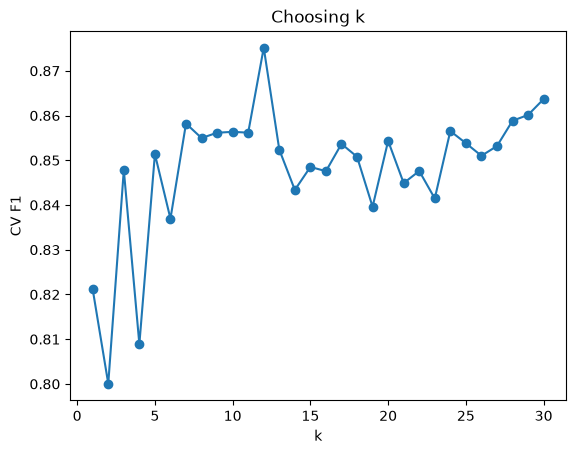

Best k: 12
Best params: {'knn__n_neighbors': 9, 'knn__p': 1, 'knn__weights': 'uniform'} | CV F1: 0.876
              precision    recall  f1-score   support

      Horeca      0.935     0.960     0.947        75
      Retail      0.909     0.857     0.882        35

    accuracy                          0.927       110
   macro avg      0.922     0.909     0.915       110
weighted avg      0.927     0.927     0.927       110

Accuracy: 0.9272727272727272
F1      : 0.8823529411764706
ROC-AUC : 0.9514285714285715


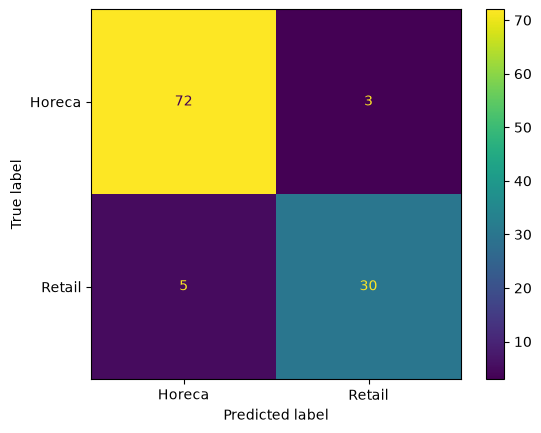

In [9]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, roc_auc_score, ConfusionMatrixDisplay)

# 1. Load and inspect
url = r"C:\IT_vedant\Machine Learning\customers.csv"
df = pd.read_csv(url)
print(df.shape); print(df.isna().sum()); print(df.describe())
print(df["Channel"].value_counts(normalize=True))

# 2. Features / target
y = (df["Channel"] == 2).astype(int)           # Retail = 1
X = df.drop(columns="Channel")
cat_cols = ["Region"]
num_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]

# 3. Preprocessing: log + scale numeric, one-hot Region
pre = ColumnTransformer([
    ("num", Pipeline([("log", FunctionTransformer(np.log1p)),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(), cat_cols),
])

# 4. Stratified split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

# 5. Choose k using cross-validation
cv = StratifiedKFold(5, shuffle=True, random_state=42)
ks = range(1, 31)
scores = []
for k in ks:
    pipe = Pipeline([("pre", pre), ("knn", KNeighborsClassifier(n_neighbors=k))])
    scores.append(cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1").mean())

plt.plot(ks, scores, marker="o"); plt.xlabel("k"); plt.ylabel("CV F1"); plt.title("Choosing k")
plt.show()
print("Best k:", ks[int(np.argmax(scores))])

# 6. Tune k, weights and metric together
pipe = Pipeline([("pre", pre), ("knn", KNeighborsClassifier())])
grid = GridSearchCV(pipe, {"knn__n_neighbors": range(3, 26, 2),
                           "knn__weights": ["uniform", "distance"],
                           "knn__p": [1, 2]},          # Manhattan vs Euclidean
                    scoring="f1", cv=cv, n_jobs=-1)
grid.fit(X_tr, y_tr)
print("Best params:", grid.best_params_, "| CV F1:", round(grid.best_score_, 3))

# 7. Final evaluation on the untouched test set
best = grid.best_estimator_
pred = best.predict(X_te)
proba = best.predict_proba(X_te)[:, 1]
print(classification_report(y_te, pred, target_names=["Horeca", "Retail"], digits=3))
print("Accuracy:", accuracy_score(y_te, pred))
print("F1      :", f1_score(y_te, pred))
print("ROC-AUC :", roc_auc_score(y_te, proba))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Horeca", "Retail"]).plot()
plt.show()